Adding Parameter Optimization
==

DIN supplement, cycling

Top-down control by zoop, virus

This version of the notebook builds on bloom_lagrangian_zoop_etal.ipynb, and adds parameter optimization.

In [1]:
import matplotlib.pyplot as plt
%matplotlib widget

In [2]:
import sys
s="/richmondvol1/rusty/stompy"
if s not in sys.path: sys.path.append(s) 
    
from importlib import reload
import time
import datetime
import os

from IPython.display import Video

import matplotlib.colorbar as cbar
import pandas as pd
import numpy as np
import xarray as xr

from scipy.integrate import solve_ivp
from matplotlib import colors, cm, ticker

from stompy import utils, memoize, xr_utils, xr_transect
import stompy.model.delft.dflow_model as dfm
import stompy.model.delft.waq_scenario as dwaq
from stompy.plot import plot_utils, plot_wkb, mkanim
import stompy.plot.cmap as scmap
from stompy.spatial import field, proj_utils
from stompy.grid import unstructured_grid

In [3]:
# These are online-coupled dfm-dwaq runs.
import bloom_common
reload(bloom_common)
from bloom_common import load_model, ratio, chl_from_RS

In [4]:
turbo_low = scmap.cmap_transform(cm.turbo,lambda i: i**0.75)

Load Supporting Data
==

In [5]:
mooring_ll=pd.read_csv("../Kd_2022/L2/latlon.csv", sep="\t").set_index('station')
mooring_ll

,latitude,longitude
station,,
Dumbarton Bridge,37.50417,-122.119
Alviso Slough,37.44000,-121.998
San Mateo Bridge,37.58444,-122.249
Guadalupe Slough,37.43468,-122.026
Newark Slough,37.51338,-122.082
Mowry Slough,37.48536,-122.033
Pond A8 outlet,37.42348,-121.980
Coyote Creek,37.46384,-122.024
Shoal,37.63079,-122.243


In [6]:
# Mooring data:
def load_mooring(site='SHL',location_name='Shoal'):
    # site: SHL, SLM, HAY, DMB, SM
    # location_name: match station column in latlon.csv.
    #  "Shoal", "SanLeandroMarina", "Hayward", "Dumbarton Bridge", "San Mateo Bridge"
    mooring_csv=f"../Kd_2022/L2/{site}_all_data_L2.csv"
    df_mooring = pd.read_csv(mooring_csv)
    del df_mooring['Unnamed: 0']
    df_mooring['time'] = pd.to_datetime(df_mooring['dt'])
    df_mooring['time'] = df_mooring.time.values # should get back to UTC

    # dt has the time zone in it, and .values should get a UTC timestamp, ready for comparison to model output
    sel=(df_mooring.time.values>np.datetime64("2022-08-01")) & (df_mooring.time.values<np.datetime64("2022-09-10"))
    df_mooring = df_mooring.iloc[sel,:] 
    df_mooring = df_mooring[ ['time','Chla_microgL','S_PSU','T_degC','Turb_FNU'] ]
    df_mooring = df_mooring.set_index('time').resample('1H').mean().reset_index()

    # For now just a single mooring, but could be multiple moorings
    df_mooring['site']=site

    lonlat = np.r_[mooring_ll.loc[location_name,'longitude'], mooring_ll.loc[location_name,'latitude']]
    xy = proj_utils.mapper('WGS84','EPSG:26910')(lonlat)
    df_mooring['x']=xy[0]
    df_mooring['y']=xy[1]
    return df_mooring

df_SHL = load_mooring('SHL',"Shoal")
df_SLM = load_mooring('SLM',"SanLeandroMarina")
df_DMB = load_mooring('DMB',"Dumbarton Bridge")
df_mooring = df_SHL

/tmp/ipykernel_3639844/86389372.py:7: DtypeWarning: Columns (57) have mixed types. Specify dtype option on import or set low_memory=False.
  df_mooring = pd.read_csv(mooring_csv)
/tmp/ipykernel_3639844/86389372.py:7: DtypeWarning: Columns (34) have mixed types. Specify dtype option on import or set low_memory=False.
  df_mooring = pd.read_csv(mooring_csv)


In [7]:
if 0:
    fig,ax = plt.subplots()

    for df in [df_SHL,df_SLM,df_DMB]:
        ax.plot(df.time, df.Chla_microgL, label=df.site.values[0])
    ax.set_ylabel(f"{df_mooring.site.values[0]} chl-a ug/l")
    ax.legend()
    fig.autofmt_xdate()

In [8]:
# Confirm mooring location
if 0:
    fig,ax=plt.subplots()
    grid=tracer_groups[0].grid
    grid.plot_edges(color='0.6',alpha=0.5,lw=0.5)
    for df in [df_SHL,df_SLM,df_DMB]:
        ax.plot(df.iloc[0].x, df.iloc[0].y,'ro')
        ax.text(df.iloc[0].x, df.iloc[0].y,df.site.values[0])
    ax.axis('off')

In [9]:
import tracer_group
reload(tracer_group)
from tracer_group import TracerGroup, tracer_groups

# Alameda release is basically zero until after the first pulse of bloom
tg = [t for t in tracer_groups if t.tag=='v17' and t.swim==6.912 and t.initial=='alameda'][0]
# But South Bay release shows up too early for DMB, SLM
#tg = [t for t in tracer_groups if t.tag=='v17' and t.swim==6.912 and t.initial=='southbay'][0]

In [10]:
grid_poly = tracer_groups[0].grid.boundary_polygon()

INFO:utils:77881/86633
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon uni

In [11]:
from stompy import memoize
class LagrangianModel:    
    # Any parameters that are available for tuning go here with defaults
    base_params=dict(
        thresh=1e-2,
        c0=3,
        kprod=1.0,
        N0=35, # initial DIN, uM
        Nsat=0.5, # half-sat DIN, uM
        Z0=0.1, # initial zoop. units?
        kmort=0.05,
        Isat=10.0,
        background=4.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        mu_Z=0.1, # growth rate for Zoop
    )

    # Which parameters to tune and their bounds
    #params_to_tune=[('c0',0.5,5),
    #            ('kprod',0.3,3.0),
    #            ('kmort',0.0,0.5),
    #            ('Isat',1.0,80),
    #            ('background',0.0,15.0),
    #            ('Nsat',0.1,5.0)]

    # expects fields in dataframe:
    # x,y -  location of the sample
    # time 
    # optionally observed values, e.g. Chla_microgL 
    df_inputs=None # determines the samples that will be simulated. 
    
    group=None # tracer group
    layer=15 # model layer requires some preprocessing and it's discrete, not available for tuning
    light_lim='mean_lim' # approach to calculating light limitation
    # 'mean_lim', 'lim_mean'. May eventually have 'mean_lim_selfshade'
    # What to report when there's not enough tracer to do anything:
    P_nodata=np.nan
    N_nodata=np.nan 
    
    def __init__(self,params={},**kw):
        # Makes a copy for this instance. So you can have the "global" defaults defined above,
        # set some "instance" defaults, and still tune some parameters with different values within
        # and instance. 
        self.base_params = self.base_params | params # params will take precedence
        utils.set_keywords(self,kw)
        assert self.df_inputs is not None,"Must specify df_inputs"
        self.prepare_inputs()
        self.parameter_sets=[]
        self.evaluate_parameter_set()

    @memoize.imemoize()
    def xy_to_cell(self,xy):
        return self.group.grid.select_cells_nearest(xy)
            
    def prepare_inputs(self):
        """
        Copy and augment df_inputs with tracer data.
        """
        xy = self.df_inputs[ ['x','y'] ].values
        cells = np.array([self.xy_to_cell(p) for p in xy])
        
        # Some may be -1
        tidx =utils.nearest(self.group.ds.time.values, self.df_inputs.time.values, max_dx = np.timedelta64(1,'h'))
        valid = tidx>=0
        
        # Filter to samples that are covered by the tracer data
        self.df_inputs = self.df_inputs.loc[ valid, :].copy()
        self.df_inputs['cell'] = cells[valid]
        self.df_inputs['tidx'] = tidx[valid]

        df_data = self.group.extract_timeseries(self.df_inputs.tidx.values, self.df_inputs.cell.values, layer=self.layer)
        for col in df_data.columns:
            self.df_inputs[col] = df_data[col].values
        self.df_inputs['conc'] = self.df_inputs['conc'].clip(0.0)        

    def evaluate_parameter_set(self,**kw):
        """
        Runs the forward model on all samples in self.df_inputs, 
        using any specified parameters, falling back to base_params.
        Returns dataframe with the results.
        kw can include any fields from base_params.
        """
        t0=time.time()
        # params that are set across an evaluation of all the data points
        params=self.base_params | kw
        self.parameter_sets.append(params) # or just log kw
            
        # ODE integration
        # State vector is [N, P, Z, I, V]
    
        recs=[]
        
        for i,row in utils.progress(enumerate(self.df_inputs.itertuples())):
            constant_params=dict(params) # make a copy so code in this loop can use df_inputs to modify parameters. 
            IC=np.r_[params['N0'], params['c0']*row.conc, params['Z0'], params['I0'], params['V0']]
            age_d=row.age_d
            # self-shading would probably mean kLight is at least partially calculated inside the
            # integration
            constant_params['kLight']=bloom_common.calc_kLight(Isat=constant_params['Isat'],
                                                               kRadA=row.kRadA,IsatA=row.IsatA,
                                                               kRadB=row.kRadB,IsatB=row.IsatB,
                                                               conc=row.conc,age_d=row.age_d)
            if np.isnan(constant_params['kLight']):
                result = np.nan*IC
            elif age_d>0:
                bunch = solve_ivp(self.npziv_diff, y0=IC, t_span=[0,row.age_d], args=(constant_params,))
                result=bunch.y[:,-1]
            else:
                result = IC
            recs.append(dict(N=result[0],
                             P=result[1]+constant_params['background'],
                             Z=result[2],
                             I=result[3],
                             V=result[4],
                             time=row.time)
                        | constant_params)
        self.df_result=pd.DataFrame(recs)
    
        elapsed=time.time() - t0
        param_str=",".join( [f'{k}={params[k]:.3f}' for k in params] )
        #print(f"solveNPZIV({param_str}) in {elapsed:.3f}s")

    # Can override in subclass
    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)

        kDIN    =  N/(N+params['Nsat'])
        dgrossP =  params['kprod']*params['kLight']*kDIN*P
        dnetP   = -params['kmort']*P + dgrossP
        dN      = -params['alpha']*dgrossP
        dZ      =  params['mu_Z']*Z
        # default derivative ignores infected and virus state
        return np.r_[dN,dnetP,dZ,0,0]
        
def fig_time_series(model, df_result=None):
    if df_result is None:
        df_result = model.df_result
    fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

    ax=axs[0]
    site = model.df_inputs.site.values[0]
    #ax.plot(model.df_observations.time, model.df_mooring.Chla_microgL, label=f'{site} mooring')
    ax.plot(model.df_inputs.time, model.df_inputs.Chla_microgL, label=f'{site} mooring')
    ax.plot(df_result.time, df_result.P, label='Lagrangian')
    ax.set_ylabel('Chl-a (ug/l)')
    ax.legend(loc='upper left')
    ax.axis(ymin=0)
    
    ax=axs[1]
    ax.plot(df_result.time, df_result.N)
    ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
    ax.axis(ymin=-0.5)
    ax=ax.twinx()
    ax.plot(df_result.time, df_result.Z,color='tab:orange')
    ax.set_ylabel('Z (-)',color='tab:orange')
    
    ax=axs[2]
    ax.plot(model.df_inputs.time, model.df_inputs.conc)
    ax.set_ylabel('Tracer conc')
    ax.axis(ymin=-0.025)
    
    ax=axs[3]
    ax.plot(df_result.time, df_result.kLight)
    ax.set_ylabel('kLight (-)')
    ax.axis(ymin=0)
    
    fig.autofmt_xdate()
    fig.subplots_adjust(top=0.98,bottom=0.1,left=0.1,right=0.87,hspace=0.07)
    return fig

def fig_time_series_with_virus(model, df_result=None):
    if df_result is None:
        df_result = model.df_result
    fig,axs = plt.subplots(4,1,sharex=True,figsize=(7,6.5))

    ax=axs[0]
    site = model.df_inputs.site.values[0]
    # Note - df_inputs is already decimated, but the corresponding df_mooring is not. Could include as optional var
    #ax.plot(model.df_mooring.time, model.df_mooring.Chla_microgL,label=f'{site} mooring')
    ax.plot(model.df_inputs.time, model.df_inputs.Chla_microgL,label=f'{site} mooring (sampled)')
    ax.plot(df_result.time, df_result.P, label='Lagrangian')
    ax.set_ylabel('Chl-a (ug/l)')
    ax.legend(loc='upper left')
    if 1: # drop outliers from limits calc
        ymax = max(model.df_inputs.Chla_microgL.quantile(0.995),
                   df_result.P.max())
        ax.axis(ymin=0,ymax=ymax)
    
    ax=axs[1]
    ax.plot(df_result.time, df_result.N)
    ax.set_ylabel('N ($\\mu$M)',color=ax.lines[0].get_color())
    ax.axis(ymin=-0.5)
    if np.any(df_result.Z>0.0):
        ax=ax.twinx()
        ax.plot(df_result.time, df_result.Z,color='tab:orange')
        ax.set_ylabel('Z (-)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=-0.01)

    has_virus=np.any(df_result.I.values>0)

    if has_virus:
        ax=axs[2]
        ax.plot(df_result.time, df_result.I, color='tab:red')
        ax.set_ylabel('Infected (ug chl/l)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
        ax=ax.twinx()
        ax.plot(df_result.time, df_result.V, color='tab:orange')
        ax.set_ylabel('Virus ($\\sim$VLP mL$^{-1}$)',color=ax.lines[0].get_color())
        plt.setp(ax.get_yticklabels(), color=ax.lines[0].get_color())
        ax.axis(ymin=0)
    else:
        axs[2].set_visible(0)

    ax=axs[3]
    ax.plot(model.df_inputs.time, model.df_inputs.conc)
    ax.set_ylabel('Tracer conc')
    ax.axis(ymin=-0.025)
    
    fig.autofmt_xdate()
    fig.subplots_adjust(top=0.98,bottom=0.1,left=0.13,right=0.87,hspace=0.07)
    return fig


# handle types of input by composition, with prepare* and plot* methods
# single mooring, multiple mooring, single RS scene, multiple RS scene.
def prepare_mooring_input(df_mooring,stride=1):
    return df_mooring.iloc[::stride].copy()

def prepare_moorings_input(dfs,stride=1):
    dfs=[prepare_mooring_input(df,stride) for df in dfs]
    return pd.concat(dfs)
    

In [12]:
class NPZIVModel(LagrangianModel):
    base_params=dict(
        N0=35, # initial DIN, uM
        # P0=c0*tracer conc
        Z0=0.1, # initial zoop. units?
        I0=0.0,
        V0=0.0,
        c0=3, # scale tracer output to get initial concentration
        kprod=1.0, # maximum instantaneous phyto growth rate [1/d]
        Nsat=0.5, # half-sat DIN, uM
        Isat=10.0, # half-sat for light, in some version(?) of W/m2
        kmortP=0.05, # phyto mortality rate [1/d]
        kmortZ=0.2, # zooplankton mortality rate [1/d]
        background=2.0, # baseline chl, added to result after the fact.
        alpha=0.15, # stoichiometry
        Z_efficiency=0.3, # growth efficiency for zoop,
        Z_max_ration=1.5, # maximum ration for zooplankton [1/d]
        mortP_to_N_efficiency = 0.5,
        N_supplement = 1.0, # uM/day
        thresh=1e-2,
        Ivlev=1.0, # Ivlev constant, 1.0  [ 1/(uM N) ]
        k_infect=0.0, # or 6.75e-8 [mL VLP^-1 day^-1] (adjust based on assumed units for P and V)default=5e-9
        lambda_lysis=1.5, # (float): Lysis rate of infected phytoplankton [day^-1]
        B=500, # viruses per 'host unit'; default=500
        k_virus=0.25, # Viral decay/inactivation rate [day^-1]
    )

    def npziv_diff(self, t, state, params):
        N,P,Z,I,V=np.clip(state,0,None)
        
        lim_DIN=N/(N+params['Nsat'])

        # No self-shading yet. 
        dgrossP = params['kprod']*params['kLight']*lim_DIN*P
        dmortP = params['kmortP']*P # positive value, but represents loss of P
        # Is this legit? Wikipedia says it is
        dgrazeP = Z*params['Z_max_ration']*(1-np.exp(-params['Ivlev']*P))

        # Virus
        # terms from basic_ode_phyto_graze_virus3.py
        # dPdt = mu_max /Kd_p * P - g * P - k * P * V
        # dIdt = k * P * V - lambda_lysis * I
        # dVdt = B * lambda_lysis * I - k * P * V - d_V * V
        # k (float): Viral infection rate constant (mL VLP^-1 day^-1).
        dinfectP = params['k_infect']*P*V
        
        dnetP = dgrossP - dmortP - dgrazeP - dinfectP

        dlyseI =  params['lambda_lysis'] * I
        
        # From DS equations, phytoplankton, when infected, are removed from P and added to I
        # at which point they lyse at a first order rate, and have no growth.
        dZ = params['Z_efficiency'] * dgrazeP - params['kmortZ']*Z
        # Wikipedia NPZ has 100% recycling efficiency for P and Z, including a (1-Z_efficiency) term
        # for "sloppy grazing"
        dN = (
            - params['alpha']*dgrossP # uptake
            + params['mortP_to_N_efficiency']*params['alpha']*dmortP # recycling
            + params['alpha'] * (1-params['Z_efficiency'])*dgrazeP
            + params['N_supplement'] # uM/day continual source
        )
        
        dI=dinfectP - dlyseI
        dV=params['B']*dlyseI - dinfectP - params['k_virus'] * V
        return np.r_[dN,dnetP,dZ,dI,dV]

INFO:utils:73857/86633
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells
INFO:UnstructuredGrid:Recalculating edge to cells


TracerGroup Extract time series
TracerGroup Extract time series


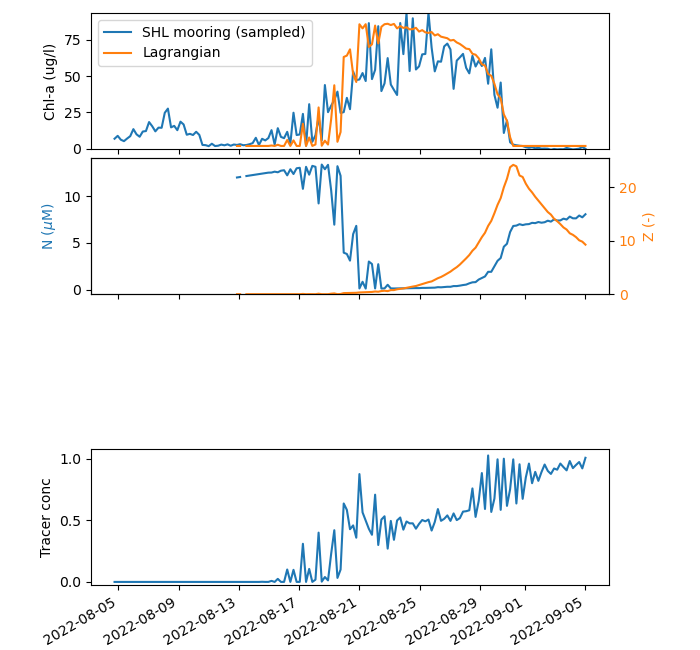

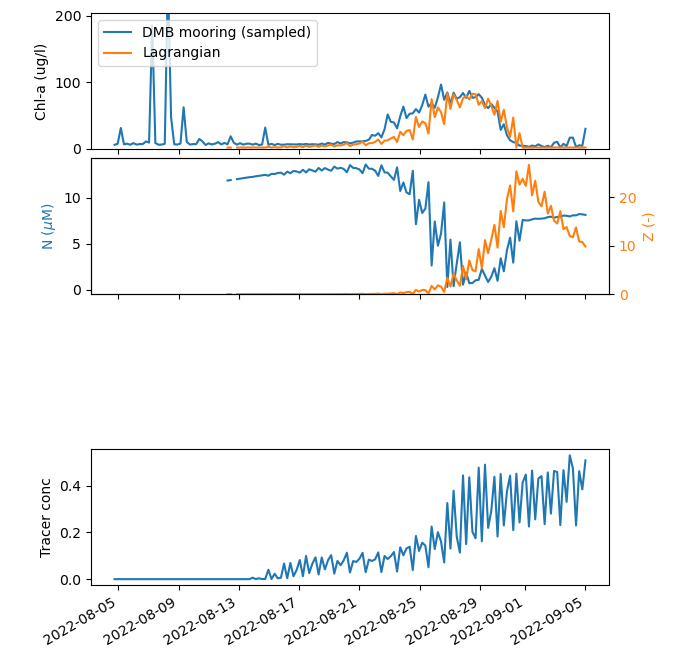

In [13]:
# An okay fit without virus.
params=dict(c0=6,I0=0, N_supplement=0.25, N0=10, kprod=1.5,Isat=5,
            Z_max_ration=2.1, Z0=0.0003)
for df in [df_SHL,df_DMB]: #,df_DMB,df_SLM]:
    model=NPZIVModel(group=tg,
                     df_inputs=prepare_mooring_input(df, stride=5),
                     params=params, layer='mean')
    fig_time_series_with_virus(model)

None


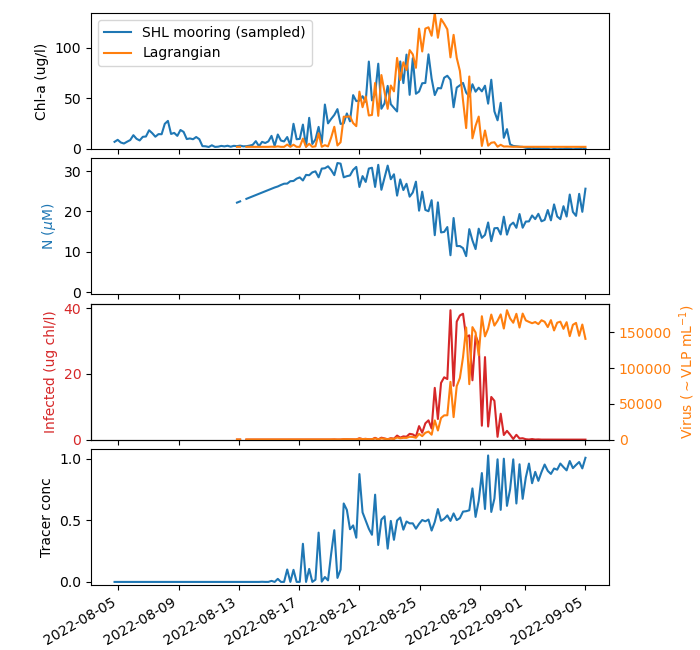

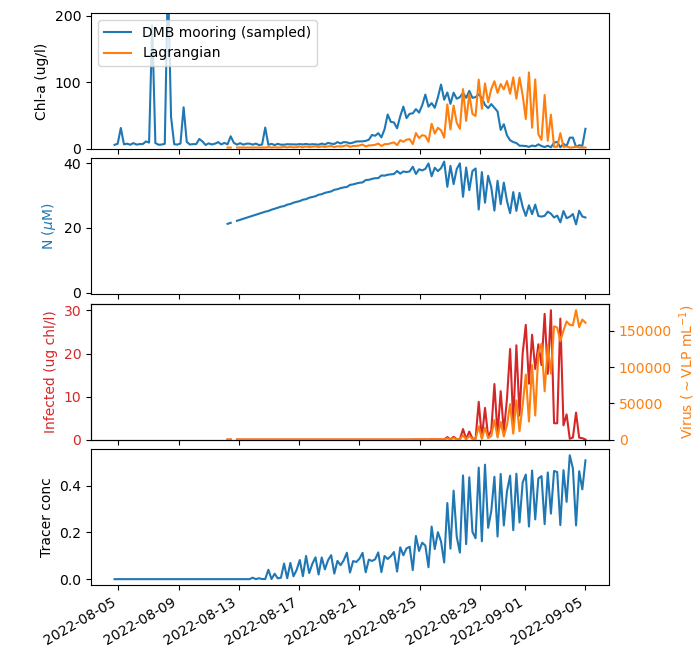

In [14]:
# Testing virus
# original starting point: 
# k_infect=8e-7  B=20_000 k_virus=0.25, lambda_lysis=4.0
# starting point based on DS email 9/30/25:
#  k_infect=1e-5, B=900, k_virus=0.025 lambda_lysis=1.50

# DMB is better with kprod=1.7 -- 1.8
# 
params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
            # virus params
            k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
            # other params
            mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
            # Can Isat help with SHL growing too fast? sort of
            Isat=20.0)
for df in [df_SHL,df_DMB]: #,df_DMB,df_SLM]:
    model=NPZIVModel(group=tg,
                     df_inputs=prepare_mooring_input(df, stride=5),
                     params=params, layer='mean')
    
    fig_time_series_with_virus(model)

None

In [15]:
# DEV for layer integrated
ds=tg.ds.dss[0]
np.diff(ds['LayCoord_w'].values)

array([0.1  , 0.1  , 0.1  , 0.1  , 0.1  , 0.1  , 0.091, 0.077, 0.06 ,
       0.046, 0.036, 0.028, 0.022, 0.017, 0.013, 0.01 ])

Spatial Results
==

In [24]:
@memoize.memoize(lru=10)
def get_fill_func(grid,cells,count):
    return grid.fill_by_smoothing_func(cells, count=count) # 10s
   

In [27]:
def fig_spatial(model,df_result=None,fig=None,fill_count=45):
    # fill_count should be about 3x stride
    if df_result is None:
        df_result=model.df_result
    chl_cmap='turbo'
    chl_clim=[0,400]
    #chl_norm=colors.PowerNorm(0.4,*chl_clim)
    chl_norm=colors.LogNorm(chl_clim[1]*0.05, chl_clim[1], True)

    t=model.df_inputs['time'].values[0] # Assumes snapshot, all same time

    if fig is None:
        fig = plt.figure(figsize=(7.5,5))
    else:
        fig.clf()
    axs = [fig.add_subplot(1,2,1), fig.add_subplot(1,2,2)]
    fig.subplots_adjust( wspace=0.04,top=0.97,right=0.97,left=0.03)

    for ax in axs: 
        ax.set_adjustable('box')
    
    ax=axs[0] # model results
    # Could cache fill_func on self
    P_result = df_result.P.values
    P_result = np.where( np.isfinite(P_result), P_result, 0.0) # fill in with 0.0
    fill_func = get_fill_func(model.group.grid,model.df_inputs.cell.values, count=fill_count) # 10s or 0.06s cached.
    
    P_filled = fill_func(P_result)
    coll=model.group.grid.plot_cells(values=P_filled, cmap=chl_cmap, norm=chl_norm, 
                                     lw=0.7,ec='face',ax=ax)
    if 1: # colorbar
        t_str = utils.strftime(t)
        cbar = plt.colorbar(coll,label="Chl-a ($\mu g \ l^{-1}$)\n"+t_str,ax=axs,orientation='horizontal',
                           pad=0.04,fraction=0.09,aspect=30)
        cax = cbar.ax
        cax.xaxis.set_minor_locator(ticker.LogLocator(subs='all'))
        cax.xaxis.set_minor_formatter(ticker.FormatStrFormatter('%d'))
        cax.xaxis.set_major_formatter(ticker.FormatStrFormatter('%d'))
    
    ax=axs[1] # RS data
    chl_rs = bloom_common.chl_from_RS(t,grid_poly)
    if chl_rs is not None:
        chl_rs.plot(ax=ax, cmap=chl_cmap, norm=chl_norm)
    
    for ax,label in zip(axs,['Lagrangian Model','Imagery']):
        ax.text(0.95,0.95,label,transform=ax.transAxes,ha='right',va='top')
    
    for ax in axs:
        ax.axis(zoom)
        plot_wkb.plot_wkb(grid_poly,lw=0.5,color='k',alpha=0.5,zorder=2, fc='none',ax=ax)
        ax.xaxis.set_visible(0)
        ax.yaxis.set_visible(0)
    return fig


In [18]:
# construct dataframe of grid locations
zoom=(547000., 591059., 4139804., 4189355.)
stride=15 # only evaluate every n'th cell
grid_poly = tg.grid.boundary_polygon() # for clipping RS data

INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon union method


In [46]:
def prepare_spatial_input(tg, tidx, zoom, stride=15):
    """
    Spatial sample for plotting -- does not include RS data
    Handles a single snapshot
    """
    # was df_grid_for_time_idx(tidx):
    t = tg.ds.time.values[tidx] 
    cells = np.nonzero(tg.grid.cell_clip_mask(zoom))[0]
    xy = tg.grid.cells_centroid(cells)    
    df_grid = pd.DataFrame()
    df_grid['cell'] = cells
    df_grid['x'] = xy[:,0]
    df_grid['y'] = xy[:,1]
    df_grid['time'] = t
    df_grid = df_grid.iloc[::stride] # solve for only a subset, then interpolate
    return df_grid

def prepare_spatial_with_RS_input(tg, tidx, zoom, stride=15, valid_range=[1.0,500.0]):
    # Expects tidx to correspond to time tg.ds.time.values[tidx] that resolves to a day with
    # good data. Note that RS data 
    df_grid = prepare_spatial_input(tg, tidx, zoom, stride=stride)
    t = tg.ds.time.values[tidx] 
    # => stompy.spatial.field.SimpleGrid
    chl_rs = bloom_common.chl_from_RS(t,tg.grid.boundary_polygon())
    assert chl_rs is not None
    xy = df_grid[ ['x','y'] ].values
    rs_data=chl_rs(xy)
    # assuming the goal is optimizing, go ahead and filter on valid data, only.
    # RS data sometimes comes in with crazy values like 20000
    valid = np.isfinite(rs_data) & (rs_data>=valid_range[0]) & (rs_data<=valid_range[1])
    df_grid = df_grid.iloc[valid,:].copy()
    df_grid['Chla_microgL'] = rs_data[valid]
    return df_grid

In [47]:
# Dev/test tuning to RS data
# virus
params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
            # virus params
            k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
            # other params
            mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
            # Can Isat help with SHL growing too fast? sort of
            Isat=20.0)
model=NPZIVModel(group=tg, 
                 df_inputs=prepare_spatial_with_RS_input(tg,tidx=534,zoom=zoom),
                 params=params)

INFO:join_features:0 open strings, 16 simple polygons
INFO:join_features:Building index
INFO:UnstructuredGrid:Warning, boundary_polygon() failed using edges!  Trying polygon union method


TracerGroup Extract multiple cells, single time step


INFO:utils:628


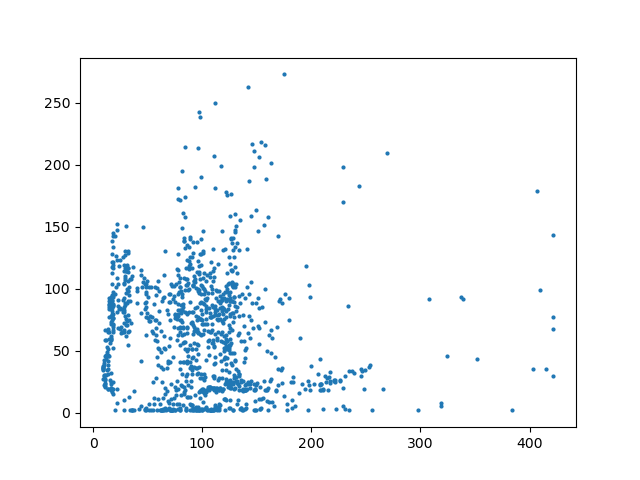

In [49]:
#len(model.df_result) # 1169 samples

fig,ax=plt.subplots()
ax.scatter(model.df_inputs['Chla_microgL'], model.df_result['P'],4)

In [20]:
# One-shot run the Lagrangian calcs for a snapshot in time, given set of 
# parameters, and plot spatial vs RS chl.
if 1: # virus
    params=dict(N0=10, c0=5, Z0=0.0000, I0=1e-4, V0=200,
                # virus params
                k_infect=1.00e-5, B=900, k_virus=0.025, lambda_lysis=1.5,
                # other params
                mortP_to_N_efficiency=0.8, N_supplement=1.5, kprod=1.6,
                # Can Isat help with SHL growing too fast? sort of
                Isat=20.0)
if 0: # basic zoop run
    params=dict(c0=6,I0=0, N_supplement=0.25, N0=10, kprod=1.5,Isat=5,
                Z_max_ration=2.1, Z0=0.0003)
model=NPZIVModel(group=tg, 
                 df_inputs=prepare_spatial_input(tg,tidx=534,zoom=zoom),
                 params=params)

TracerGroup Extract multiple cells, single time step


INFO:utils:706
INFO:utils:1203
INFO:utils:1715


Time to get fill function: 0.06s


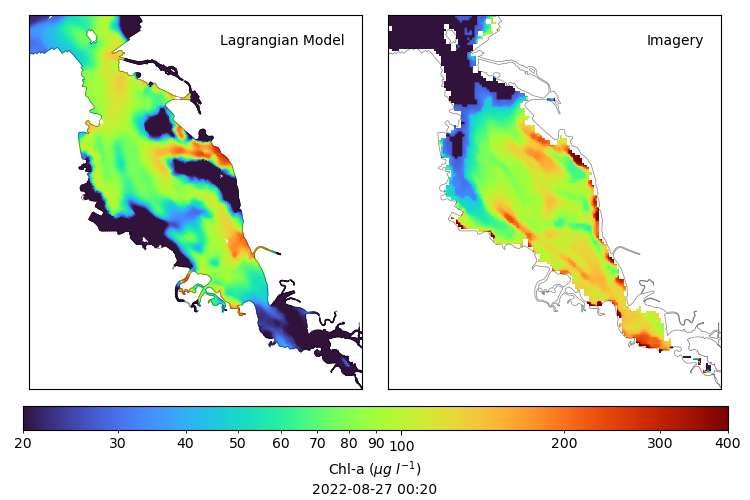

In [28]:
fig_spatial(model) ;

In [ ]:
# Prepare inputs for optimizing against RS data:


In [ ]:
# Render animation
frame_dir = "frames-bloom_lagrangian_zoop_etal-v002"
force=True # overwrite existing images, but does not proactively delete existing.

if not os.path.exists(frame_dir):
    os.makedirs(frame_dir)
    
with open(os.path.join(frame_dir,'params.txt'),'wt') as fp:
    fp.write("\n".join([
        "Parameters:",
        str(params),
        f"Run dir: {tg.run_dir}",
        f"Tracer suffix: {tg.suffix}",
        f"Swim speed: {tg.swim}",
        f"Initial condition: {tg.initial}",
       ]))
    
times=tg.ds.time.values # all times available in the tracer run
tidxs = np.arange(len(times)) # 
#time_sel = slice(None,None,72) # start idx, stop idx, stride of 3 days
time_sel = slice(None,None) # hourly, start to finish
fig=None
for frame,(tidx,t) in enumerate(zip( tidxs[time_sel], times[time_sel])):
    img_fn=os.path.join(frame_dir,f"frame{frame:04d}.png")
    if os.path.exists(img_fn) and not force:
        print("skipping existing image")
        continue
    df_grid_tidx=df_grid_for_time_idx(tidx)
    tuner=NPZIVModel(group=tg, df_mooring=df_grid_tidx, stride=1, params=params)
    fig = tuner.fig_last_eval_spatial(fig=None)
    fig.savefig(img_fn,dpi=100)

INFO:utils:1729
INFO:utils:1717
INFO:utils:1739
INFO:utils:1900
INFO:utils:2034
INFO:utils:1803
INFO:utils:1736
INFO:utils:1650
INFO:utils:1594
INFO:utils:1563
INFO:utils:1611
INFO:utils:1642
INFO:utils:1663
INFO:utils:1730
INFO:utils:1731
INFO:utils:1745
INFO:utils:1807
INFO:utils:1726
INFO:utils:1659
INFO:utils:1586
INFO:utils:1497
INFO:utils:1451
INFO:utils:1462
INFO:utils:1458
INFO:utils:1476
INFO:utils:1477
INFO:utils:1464
INFO:utils:1484
INFO:utils:1506
INFO:utils:1493
INFO:utils:1496
INFO:utils:1462
INFO:utils:1444
INFO:utils:1451
INFO:utils:1444
INFO:utils:1441
INFO:utils:1447
INFO:utils:1440
INFO:utils:1434
INFO:utils:1450
INFO:utils:1447
INFO:utils:1448
INFO:utils:1439
INFO:utils:1434
INFO:utils:1428
INFO:utils:1400
INFO:utils:1386
INFO:utils:1382
INFO:utils:1390
INFO:utils:1392
INFO:utils:1386
INFO:utils:1377
INFO:utils:1374
INFO:utils:1389
INFO:utils:1399
INFO:utils:1399
INFO:utils:1388
INFO:utils:1365
INFO:utils:1375
INFO:utils:1367
INFO:utils:1365
INFO:utils:1359
INFO:uti

TracerGroup Extract multiple cells, single time step


INFO:utils:1084
INFO:utils:1805


TracerGroup Extract multiple cells, single time step


INFO:utils:1081
INFO:utils:1786


...

TracerGroup Extract multiple cells, single time step


INFO:utils:842
INFO:utils:1392


TracerGroup Extract multiple cells, single time step


INFO:utils:837
INFO:utils:1384


TracerGroup Extract multiple cells, single time step


In [186]:
# Compile frames into movie
movie_out=os.path.join(frame_dir,'output.mp4')
mkanim.mkanim(movie_out,frame_dir+"/frame%04d.png")

ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

In [191]:
# Display resulting animation
Video(movie_out)

NPZIV Notes
==



In [87]:
# Stoichiometry for DIN vs chl
alpha1 = 6.625 # = 1mol N * 106molC/16 mol N = mol C ; 1mol CO2 fixed * 1mol O2 / 1mol CO2 , 1:1
c_chl = 1/0.03
alpha2 = alpha1*12/c_chl # = 2.385 ug chl / umol N ....106 umol C / 16 umol N * 12 ug C / umol C * 0.03 ug chl / 1 ug
alpha2
1.0/alpha2 # uM DIN / ug/l Chl-a

0.41928721174004197

Diagnostics for tidal phase
==

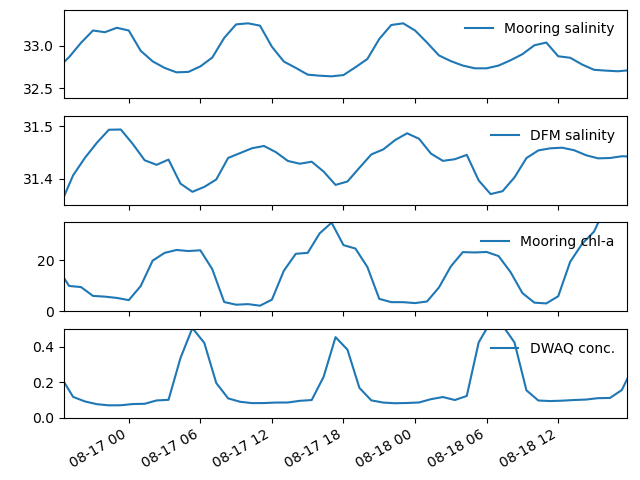

In [215]:
# Is there enough salt to diagnose phase? yes - and phase appears correct.
fig,axs=plt.subplots(4,1,sharex=True)
axs[0].plot( df_mooring.time, df_mooring.S_PSU, label='Mooring salinity')

axs[1].plot( tg.ds.time.values, tg.ds['sa1'].isel(laydim=15,nFlowElem=16145),
           label='DFM salinity')

axs[2].plot( df_mooring.time, df_mooring.Chla_microgL,label='Mooring chl-a')

axs[3].plot( tg.ds.time.values, tg.ds[f'conc{tg.suffix}'].isel(laydim=15,nFlowElem=16145),
           label='DWAQ conc.')

for ax in axs:
    ax.legend(loc='upper right', frameon=0)
    
fig.autofmt_xdate()
axs[0].axis((19220.7738, 19222.7409, 32.38, 33.43))
axs[1].axis(ymin=31.35,ymax=31.52)
axs[2].axis(ymin=0,ymax=35)
axs[3].axis(ymin=0,ymax=0.5)
fig.subplots_adjust(right=0.98,bottom=0.13,top=0.98,left=0.10)


Vertical mixing of P vs N
==

Most of the Lagrangian analysis to date has considered a single layer in isolation.

In reality, the vertical distribution is dynamic, and we're more interested in the
water-column averaged growth, optionally transformed to reflect the surface concentration
for comparison to RS data.

The integration expects initial values for $N$, $P$, $Z$, $I$, and $V$, with $P$ 
based on tracer results.

Tracer results additionally provide $k_{light}$, based on light tracers.





            constant_params['kLight']=bloom_common.calc_kLight(Isat=constant_params['Isat'],
                                                               kRadA=row.kRadA,IsatA=row.IsatA,
                                                               kRadB=row.kRadB,IsatB=row.IsatB,
                                                               conc=row.conc,age_d=row.age_d)